# How exposed is a company to climate change?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/how_exposed_is_this_company.ipynb)

**The question:** *"I own shares in Walmart (or lend to it). How exposed is it to
climate change, and how does it compare with other big companies?"*

A company's physical climate risk comes from three things multiplied together:

1. **Where its buildings are** (exposure),
2. **what weather hits those places** (hazard), and
3. **how much damage that weather does** (vulnerability, written as a *damage function*).

We answer three times, each with a better data source, using the same open
toolkit, [crc-sdk](https://github.com/RiskThinking/crc-sdk):

| | Data | What it can tell you |
|---|---|---|
| **A** | Free public data: Overture Maps places and NOAA hurricane tracks | Where the company's stores are, and which ones hurricanes have hit since 1990 |
| **B** | **CRC Open**: free, ready-made climate curves, plus open damage functions | Expected yearly damage at each store, now and in 2070–2080, under a high-emissions future (SSP5-8.5; [other futures on request](mailto:opensource@riskthinking.ai)) |
| **C** | **CDT**, Riskthinking.AI's Climate Digital Twin (enterprise) | The whole company, every asset it owns worldwide, for several emissions futures, ranked against a market index |

We use Walmart's stores in Florida for A and B: a public company, a state that
hurricanes know well. Run it on Colab with **Runtime → Run all**; no account
needed for A and B. Change `BRAND`, `AREA` and `REGION` to look at another
company or place.

## Setup

In [1]:
#@title Install packages (Colab) and choose a company
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "crc-sdk[geometry]>=0.11.1,<1", "plotly>=6,<7", "velo-sdk",
    ])

BRAND = "Walmart"                       # brand name as it appears on Overture Maps
COMPANY = "Walmart"                     # company name in CDT (part C)
INDEX = "Dow Jones Industrial Average"  # market index to compare against (part C)
REGION = "FL"                           # keep places whose address is in this state
CATEGORIES = ["superstore", "department_store", "food_and_beverage_store", "discount_store"]

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"
AREA = (-82.9, 27.6, -82.2, 28.3) if CI else (-87.7, 24.4, -79.9, 31.1)  # Tampa Bay / all of Florida
HURRICANES_SINCE = 1990
EARLY, LATE = (2025, 2030, 2035), (2070, 2075, 2080)

In [2]:
import json
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.parquet as pq
from plotly.subplots import make_subplots

from crc_sdk.connectors.duckdb import DuckDBConnection, sql_quote
from crc_sdk.impacts import ImpactContext, impacts
from crc_sdk.workflows import HazardDataset, IBTrACSPlan, ImpactContextColumns

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

DATA = Path("data") / "company"
DATA.mkdir(parents=True, exist_ok=True)

INK, MUTED, BLUE, ORANGE, GREEN = "#52514e", "#d6d5d1", "#2a78d6", "#eb6834", "#1baf7a"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def layout(fig, title, **kwargs):
    settings = dict(height=480, margin=dict(l=70, r=30, t=70, b=60)) | kwargs
    fig.update_layout(title=dict(text=title, x=0.01), font=FONT, **settings)
    return fig


def store_map(values, title, colorbar, colorscale="YlOrRd"):
    fig = go.Figure(go.Scattergeo(
        lon=stores["longitude"], lat=stores["latitude"], mode="markers",
        text=stores["city"], customdata=values,
        marker=dict(size=8, color=values, colorscale=colorscale, line=dict(width=0.5, color="white"),
                    colorbar=dict(title=colorbar)),
        hovertemplate="%{text}: %{customdata}<extra></extra>",
    ))
    fig.update_geos(scope="usa", fitbounds="locations", showland=True, landcolor="#f4f3f0",
                    showlakes=False, subunitcolor="#bdbcb8")
    return layout(fig, title, margin=dict(l=10, r=10, t=70, b=10), height=520)

## A. Ask free public data

### Where are the stores?

[Overture Maps](https://overturemaps.org/) publishes an open map of more than 60
million places worldwide, including the brand behind each shop. crc-sdk's DuckDB
connection reads it straight from the cloud, keeping only the area we ask for.

In [3]:
def read_json(url):
    with urllib.request.urlopen(url, timeout=60) as response:
        return json.load(response)


release = read_json("https://stac.overturemaps.org/catalog.json")["latest"]
collection = read_json(f"https://stac.overturemaps.org/{release}/places/place/collection.json")
files = []
for link in collection["links"]:
    if link.get("rel") == "item":
        item = read_json(link["href"])
        west, south, east, north = item["bbox"]
        if not (east < AREA[0] or west > AREA[2] or north < AREA[1] or south > AREA[3]):
            files.append(item["assets"]["aws"]["href"])

connection = DuckDBConnection.for_analytics(DATA).connect()
stores = connection.execute(f"""
    SELECT id AS asset_id, names.primary AS name, basic_category AS category,
           addresses[1].locality AS city, bbox.xmin AS longitude, bbox.ymin AS latitude
    FROM read_parquet([{", ".join(sql_quote(f) for f in files)}])
    WHERE bbox.xmin BETWEEN {AREA[0]} AND {AREA[2]} AND bbox.ymin BETWEEN {AREA[1]} AND {AREA[3]}
      AND lower(brand.names.primary) = lower({sql_quote(BRAND)})
      AND addresses[1].region = {sql_quote(REGION)}
      AND basic_category IN ({", ".join(sql_quote(c) for c in CATEGORIES)})
    ORDER BY id
""").df()
print(f"{len(stores)} {BRAND} stores in {REGION} (Overture release {release})")
stores["category"].value_counts()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

322 Walmart stores in FL (Overture release 2026-10-21.0)


category
food_and_beverage_store    140
department_store           114
superstore                  64
discount_store               4
Name: count, dtype: int64

### Which stores have hurricanes hit?

NOAA's [IBTrACS](https://www.ncei.noaa.gov/products/international-best-track-archive)
records the track and strength of every tropical storm. We keep the stretches
where a storm blew at **hurricane strength** (at least 64 knots, about 119 km/h)
and count, for each store, how many hurricanes passed within **50 km**.

In [4]:
plan = IBTrACSPlan("NA", DATA / "ibtracs").years(HURRICANES_SINCE, 2100)
plan.prefetch()
track = pa.Table.from_batches(list(plan.batches())).select(
    ["SID", "SEASON", "NAME", "ISO_TIME", "LAT", "LON", "USA_WIND"]).to_pandas()
for column in ("LAT", "LON", "USA_WIND"):
    track[column] = pd.to_numeric(track[column], errors="coerce")
track = track.dropna().sort_values(["SID", "ISO_TIME"])
track = track[track["LON"].between(AREA[0] - 1, AREA[2] + 1) & track["LAT"].between(AREA[1] - 1, AREA[3] + 1)]

# Fill in points every ~10 km between the 3-hourly fixes, where both ends are hurricane strength.
steps = np.linspace(0, 1, 8, endpoint=False)
pieces = []
for sid, storm in track.groupby("SID"):
    a, b = storm.iloc[:-1], storm.iloc[1:]
    strong = (np.minimum(a["USA_WIND"].values, b["USA_WIND"].values) >= 64)
    lat = a["LAT"].values[strong, None] + (b["LAT"].values - a["LAT"].values)[strong, None] * steps
    lon = a["LON"].values[strong, None] + (b["LON"].values - a["LON"].values)[strong, None] * steps
    if strong.any():
        pieces.append(pd.DataFrame({"sid": sid, "name": f"{storm['NAME'].iloc[0].title()} {storm['SEASON'].iloc[0]}",
                                    "lat": lat.ravel(), "lon": lon.ravel()}))
path = pd.concat(pieces)


def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


near = distance_km(stores["latitude"].values[:, None], stores["longitude"].values[:, None],
                   path["lat"].values[None, :], path["lon"].values[None, :]) <= 50
hits = [set(path["name"].values[row]) for row in near]
stores["hurricanes"] = [len(h) for h in hits]

years = pd.Timestamp.now().year - HURRICANES_SINCE
typical = stores["hurricanes"].median()
storms = pd.Series([name for h in hits for name in h]).value_counts()
print(f"Since {HURRICANES_SINCE}, a hurricane passed within 50 km of "
      f"{(stores['hurricanes'] > 0).mean():.0%} of these stores.")
if typical:
    print(f"The typical store saw {typical:.0f}: about one every {years / typical:.0f} years.")
print("Storms that came close to the most stores:", ", ".join(f"{n} ({c})" for n, c in storms.head(3).items()))

Since 1990, a hurricane passed within 50 km of 81% of these stores.
The typical store saw 2: about one every 18 years.
Storms that came close to the most stores: Milton 2024 (90), Charley 2004 (83), Irene 1999 (78)


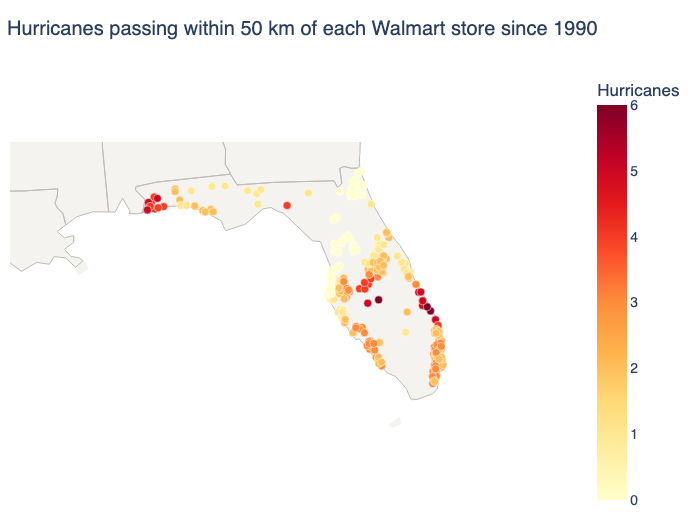

In [5]:
fig = store_map(stores["hurricanes"], f"Hurricanes passing within 50 km of each {BRAND} store since {HURRICANES_SINCE}",
                "Hurricanes")
fig.show()

> 💡 **Key idea: exposure is about place.** The same store design faces very
> different weather depending on where it stands. Stores on the southern and
> Gulf coasts sit in hurricane alley; stores in the north of the state much less.

**What A leaves out:** only the past, only hurricanes, and no sense of *damage*:
a store that sees two weak hurricanes may suffer less than one that sees a
single strong one. Overture also shows where a brand **operates**, not what the
company owns or what each building is worth.

## B. Ask CRC Open, with damage functions

[CRC Open](https://github.com/RiskThinking/crc-sdk/blob/main/docs/sources/crc-open.md)
gives a ready-made **climate risk curve** for 63 hazards on a fine grid, for
2025–2100 under SSP5-8.5. Here we use three that matter for a store:

| Hazard | CRC Open name | Measured as |
|---|---|---|
| Hurricane wind | `cyclone` | strongest wind of the year (m/s) |
| Heavy rain | `rx1day` | wettest day of the year (mm) |
| Heat | `hot_days` | number of hot days in the year |

New to these curves? The five-minute
[primer](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/climate_risk_curves_primer.ipynb) explains them.

### From weather to damage

A **damage function** turns a hazard value into the share of a building's value
lost. crc-framework ships open, published damage functions; crc-sdk applies them
to every store in one step. Here is what they look like for a commercial
building in the USA:

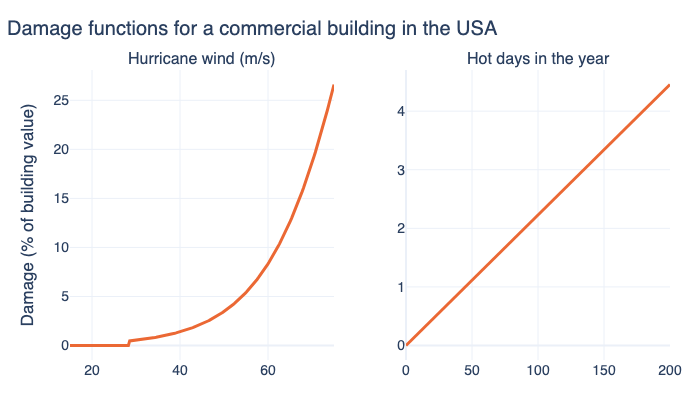

In [6]:
context = ImpactContext(country="USA", continent="North America", building_type="commercial")
curves = {
    "cyclone": ("Hurricane wind (m/s)", np.linspace(15, 75, 200)),
    "hot_days": ("Hot days in the year", np.linspace(0, 200, 200)),
}
fig = make_subplots(rows=1, cols=2, subplot_titles=[label for label, _ in curves.values()],
                    horizontal_spacing=0.12)
for col, (hazard, (label, x)) in enumerate(curves.items(), start=1):
    damage = np.asarray(impacts.for_factor(hazard, context=context).evaluate(x), dtype=float)
    fig.add_trace(go.Scatter(x=x, y=100 * damage, mode="lines", line=dict(color=ORANGE, width=3),
                             hovertemplate="%{x:.0f} → %{y:.1f}% of building value<extra></extra>",
                             showlegend=False), row=1, col=col)
fig.update_yaxes(title_text="Damage (% of building value)", row=1, col=1)
layout(fig, "Damage functions for a commercial building in the USA", height=420)
fig.show()

> 💡 **Key idea: hazard is not damage.** Damage rises slowly at first, then
> steeply: a 40 m/s gust breaks a few things, a 70 m/s one tears roofs off. So a
> small change in the rarest, strongest storms can matter more than a big change
> in everyday weather. (The heavy-rain function depends on each location's usual
> rainfall, so crc-sdk fills it in per store.)

### Expected damage: the average year's repair bill

Each store's climate curve covers every kind of year, from calm to extreme. Run
every one of those years through the damage function and average: that is the
**expected yearly damage**, the repair bill in an average year as a share of the
building's value. (Insurers call it the *average annual loss*.) We do it for
2025–2035 and 2070–2080, averaging three horizons in each window because single
years are noisy.

In [7]:
HAZARDS = {"cyclone": "Hurricane wind", "rx1day": "Heavy rain", "hot_days": "Hot days"}
# 200 equally likely kinds of year, from the calmest to about 1-in-400.
RETURN_PERIODS = [float(1 / (1 - p)) for p in (np.arange(200) + 0.5) / 200]

assets = pa.Table.from_pandas(stores[["asset_id", "longitude", "latitude"]].assign(
    country="USA", continent="North America", building_type="commercial"), preserve_index=False)
bounds = (stores["longitude"].min() - 0.1, stores["latitude"].min() - 0.1,
          stores["longitude"].max() + 0.1, stores["latitude"].max() + 0.1)

damage = {}
for hazard in HAZARDS:
    plan = (HazardDataset.crc_open().for_area(bounds).hazards([hazard])
            .horizons([*EARLY, *LATE]).cache(DATA / "crc-open", mode="reuse"))
    output = DATA / f"{hazard}_damage.parquet"
    output.unlink(missing_ok=True)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        result = plan.for_assets(assets).return_periods(RETURN_PERIODS).impact(
            impacts.for_factor(hazard),
            context=ImpactContextColumns(country="country", continent="continent", building_type="building_type"),
            name=f"{hazard}_damage", value_unit="fraction", value_semantics="damage ratio",
        ).write_parquet(output)
    table = pq.read_table(output).to_pandas()
    table["expected"] = 100 * table[list(result.value_columns)].mean(axis=1)
    table["window"] = np.where(table["horizon"].isin(EARLY), "2025–2035", "2070–2080")
    damage[hazard] = table.groupby(["asset_id", "window"])["expected"].mean().unstack()

total = sum(damage.values())
stores = stores.set_index("asset_id")
stores["damage_early"], stores["damage_late"] = total["2025–2035"], total["2070–2080"]
stores = stores.reset_index()
# Averages add up across hazards and stores, so we report the average store.
summary = pd.DataFrame({HAZARDS[h]: d.mean() for h, d in damage.items()}).T
summary.loc["All three (average store)"] = total.mean()
summary.round(2)

window,2025–2035,2070–2080
Hurricane wind,0.70,0.70
Heavy rain,0.02,0.03
Hot days,0.06,0.86
All three (average store),0.79,1.59


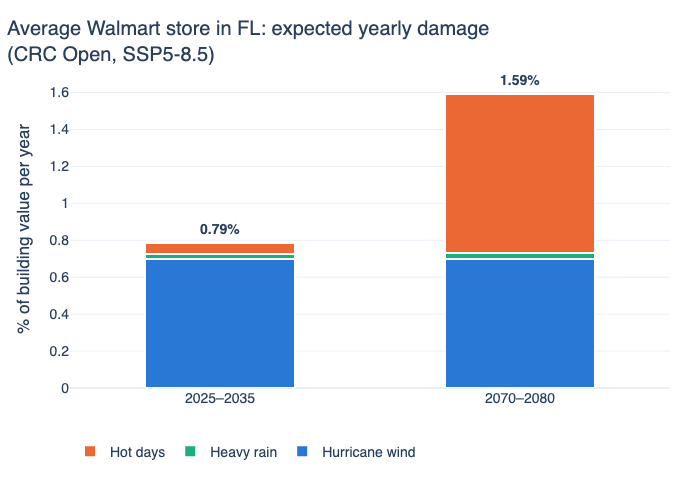

The average store's expected yearly damage goes from 0.79% of its value in 2025–2035 to 1.59% in 2070–2080, 2.0 times as much.


In [8]:
fig = go.Figure()
colors = {"cyclone": BLUE, "rx1day": GREEN, "hot_days": ORANGE}
for hazard, label in HAZARDS.items():
    values = damage[hazard].mean()
    fig.add_trace(go.Bar(x=values.index, y=values.values, name=label, marker_color=colors[hazard],
                         marker_line=dict(color="white", width=2),
                         hovertemplate=label + ": %{y:.2f}%<extra></extra>"))
for window, value in total.mean().items():
    fig.add_annotation(x=window, y=value, text=f"<b>{value:.2f}%</b>", showarrow=False, yshift=14)
layout(fig, f"Average {BRAND} store in {REGION}: expected yearly damage<br>(CRC Open, SSP5-8.5)",
       barmode="stack", yaxis_title="% of building value per year", bargap=0.5,
       legend=dict(orientation="h", y=-0.15))
fig.show()
early, late = total.mean()
print(f"The average store's expected yearly damage goes from {early:.2f}% of its value in 2025–2035 "
      f"to {late:.2f}% in 2070–2080, {late / early:.1f} times as much.")

CRC Open's hurricane curves describe today's climate at every horizon, so the
hurricane share stays flat; the growth comes from heat. Where are the stores
with the biggest bill by 2070–2080?

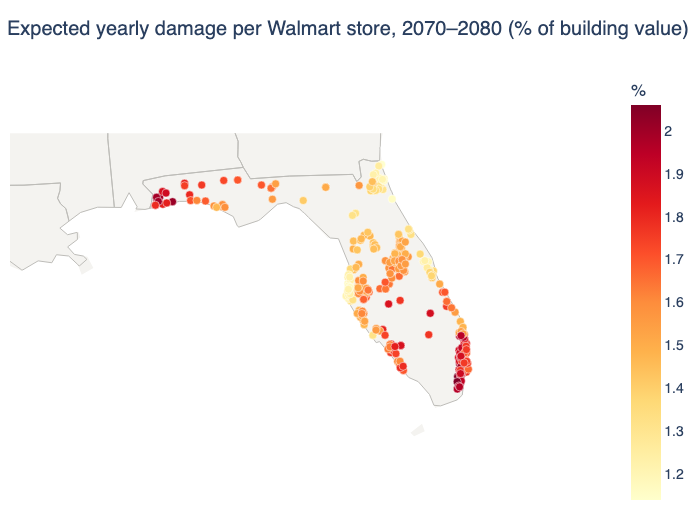

In [9]:
fig = store_map(stores["damage_late"].round(2),
                f"Expected yearly damage per {BRAND} store, 2070–2080 (% of building value)", "%")
fig.show()

### Do A and B agree?

A counted hurricanes in the record; B's hurricane damage comes from fitted
curves. If both are sound, stores that hurricanes hit more often in the past
should carry more expected hurricane damage in B.

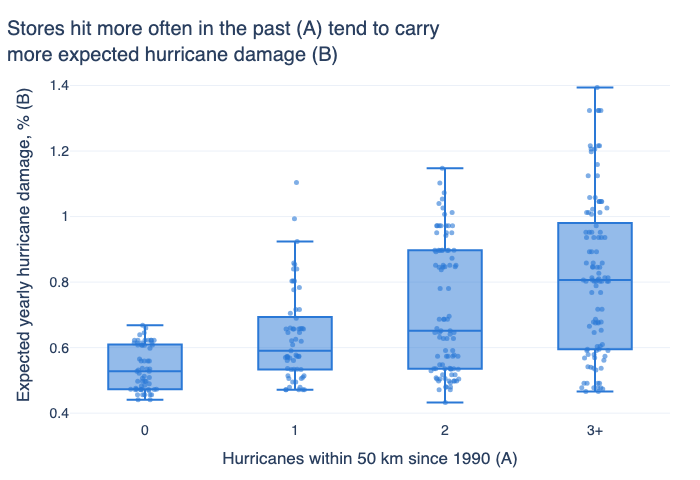

Median expected hurricane damage by number of past hurricanes: 0: 0.53%, 1: 0.59%, 2: 0.65%, 3+: 0.81%


In [10]:
check = stores[["hurricanes"]].assign(cyclone=damage["cyclone"]["2025–2035"].reindex(stores["asset_id"]).values)
check["group"] = check["hurricanes"].clip(upper=3).map(lambda n: "3+" if n == 3 else str(n))
by_group = check.groupby("group")["cyclone"].median()
agree = by_group.iloc[-1] > by_group.iloc[0]
title = ("Stores hit more often in the past (A) tend to carry<br>more expected hurricane damage (B)" if agree
         else "Past hurricane counts (A) and expected hurricane damage (B)<br>don't line up clearly here")
fig = go.Figure(go.Box(x=check["group"], y=check["cyclone"], marker_color=BLUE, boxpoints="all",
                       jitter=0.4, pointpos=0, marker=dict(size=5, opacity=0.6), line=dict(width=2),
                       hovertemplate="%{x} hurricanes: %{y:.2f}%<extra></extra>"))
layout(fig, title, xaxis=dict(title=f"Hurricanes within 50 km since {HURRICANES_SINCE} (A)",
                              categoryorder="array", categoryarray=["0", "1", "2", "3+"]),
       yaxis_title="Expected yearly hurricane damage, % (B)")
fig.show()
print("Median expected hurricane damage by number of past hurricanes: "
      + ", ".join(f"{g}: {v:.2f}%" for g, v in by_group.items()))
if not agree:
    print("A small area has few storms, so 35 years of history is a noisy guide; try a larger AREA.")

**What B adds over A:** the future, more hazards with the same code, and
**damage** in place of counts: a number per store you can add up across a
portfolio, compare between companies or feed into a valuation.

**What B leaves out:**

- one emissions pathway (SSP5-8.5) and no historical baseline;
- three of the 63 hazards here (floods, wildfire and sea level need care and
  are left out);
- an open map of stores, not the company's own list of what it owns or what
  each building is worth (we assumed equal values);
- damage averages add up across stores, but bad years do not: a hurricane that
  hits one store often hits its neighbours too.

Need other pathways? See part C, or ask
[opensource@riskthinking.ai](mailto:opensource@riskthinking.ai) about more CRC Open data.

## C. Ask CDT

**CDT** (Climate Digital Twin) is Riskthinking.AI's enterprise service. It
already maps the assets of thousands of listed companies worldwide and scores
each company across many hazards and every emissions future. Three of its
scores, all for the whole company:

| Score | Meaning |
|---|---|
| **Expected impact** | average damage, as a share of tangible asset value |
| **Tail risk** (CVaR 95%) | average damage in the worst 5% of outcomes |
| **Downside likelihood** | chance of more damage than around 2010 |

CDT measures damage on its own basis, across more hazards and every asset, so
compare companies and futures with these scores rather than with part B's
numbers.

The saved results below come from a CDT run: two small tables and two charts.
To run it yourself you need an API key; [start a CDT Express trial](https://velo.riskthinking.ai/cdt-express)
to get one. In Colab, store it as a secret named `RISKTHINKING_API_KEY`. Without a
key the cells explain how to get one and skip.

Prefer chatting to coding? Connect the [CDT Express MCP server](https://github.com/RiskThinking/cdt-express-mcp)
to Claude or ChatGPT and ask: *"Which Dow companies face the most physical climate risk by 2050?"*

In [11]:
api_key = os.environ.get("RISKTHINKING_API_KEY")
if api_key is None and IN_COLAB:
    from google.colab import userdata
    try:
        api_key = userdata.get("RISKTHINKING_API_KEY")
    except Exception:
        api_key = None

scores = ranking = None
if api_key:
    from velo_sdk.api import APIClient

    client = APIClient(api_key=api_key)
    METRICS = "expected_impact,cvar_95,dcr_score"
    company = next(c for c in client.get("/companies/search", params={"name": COMPANY})["results"]
                   if c["name"].lower().startswith(COMPANY.lower()))
    rows = []
    for pathway in ("ssp245", "ssp585"):
        for horizon in ("2030", "2050", "2090"):
            r = client.get(f"/companies/{company['id']}/climate/scores",
                           params={"pathway": pathway, "horizon": horizon, "metric": METRICS})
            rows.append({"pathway": pathway, "horizon": int(horizon),
                         "Expected impact %": 100 * r["expected_impact"],
                         "Tail risk (CVaR 95%) %": 100 * r["cvar_95"],
                         "Downside likelihood %": 100 * r["dcr_score"]})
    scores = pd.DataFrame(rows)

    index = next(i for i in client.get("/markets/indexes/search", params={"name": INDEX})["results"]
                 if i["name"] == INDEX)
    r = client.get(f"/markets/indexes/{index['id']}/companies/climate/scores", params={
        "pathway": "ssp585", "horizon": "2050", "metric": METRICS,
        "sort_by": "expected_impact", "sort_direction": "descending", "limit": 100})
    ranking = pd.DataFrame([{"company": c["company_name"], "Expected impact %": 100 * c["expected_impact"]}
                            for c in r["results"]])
    print(company["name"])
    display(scores.set_index(["pathway", "horizon"]).round(1))
else:
    print("No RISKTHINKING_API_KEY found, so section C is skipped.")
    print("Start a trial at https://velo.riskthinking.ai/cdt-express.")

Walmart Inc


Expected impact %  Tail risk (CVaR 95%) %  \
pathway horizon                                              
ssp245  2030                   9.9                    20.3   
        2050                  10.8                    20.7   
        2090                  12.0                    21.2   
ssp585  2030                  11.3                    22.8   
        2050                  12.4                    22.8   
        2090                  15.6                    25.8   

                 Downside likelihood %  
pathway horizon                         
ssp245  2030                      81.3  
        2050                      89.6  
        2090                      94.2  
ssp585  2030                      85.9  
        2050                      95.3  
        2090                      98.7

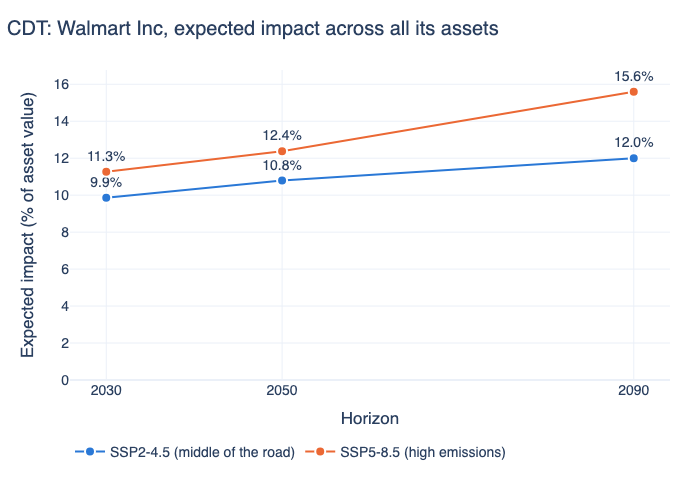

In [12]:
if scores is not None:
    labels = {"ssp245": "SSP2-4.5 (middle of the road)", "ssp585": "SSP5-8.5 (high emissions)"}
    fig = go.Figure()
    for pathway, color in (("ssp245", BLUE), ("ssp585", ORANGE)):
        frame = scores[scores["pathway"] == pathway]
        fig.add_trace(go.Scatter(x=frame["horizon"], y=frame["Expected impact %"], name=labels[pathway],
                                 mode="lines+markers+text", line=dict(color=color, width=2),
                                 marker=dict(size=10, line=dict(width=2, color="white")),
                                 text=[f"{v:.1f}%" for v in frame["Expected impact %"]],
                                 textposition="top center", hovertemplate="%{x}: %{y:.1f}%<extra></extra>"))
    layout(fig, f"CDT: {company['name']}, expected impact across all its assets",
           xaxis=dict(title="Horizon", tickvals=[2030, 2050, 2090]),
           yaxis=dict(title="Expected impact (% of asset value)", rangemode="tozero"),
           legend=dict(orientation="h", y=-0.18))
    fig.show()

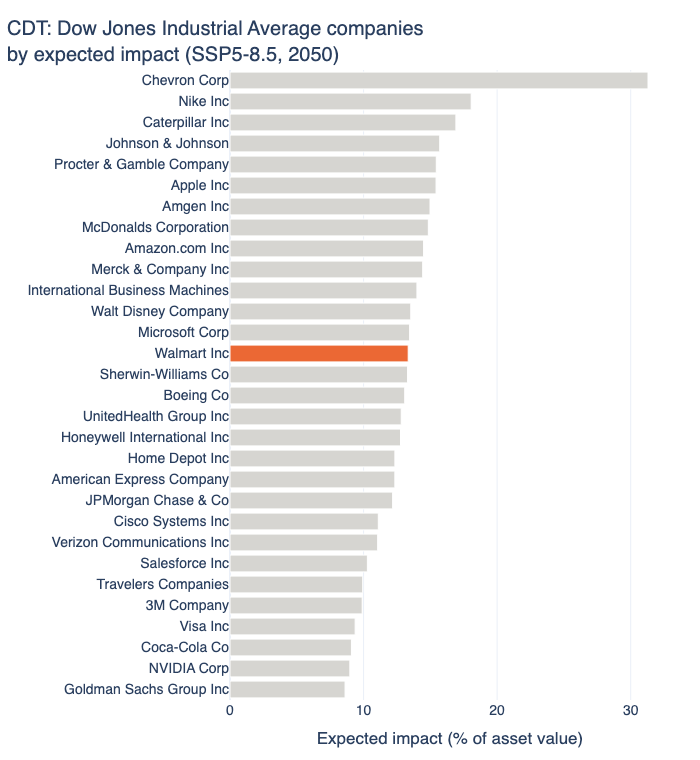

Walmart Inc ranks 14 of 30; highest: Chevron Corp, lowest: Goldman Sachs Group Inc.


In [13]:
if ranking is not None:
    ranked = ranking.sort_values("Expected impact %")
    highlight = [ORANGE if name == company["name"] else MUTED for name in ranked["company"]]
    fig = go.Figure(go.Bar(x=ranked["Expected impact %"], y=ranked["company"], orientation="h",
                           marker=dict(color=highlight, line=dict(color="white", width=1)),
                           hovertemplate="%{y}: %{x:.1f}%<extra></extra>"))
    layout(fig, f"CDT: {INDEX} companies<br>by expected impact (SSP5-8.5, 2050)",
           xaxis_title="Expected impact (% of asset value)", height=760,
           margin=dict(l=230, r=30, t=70, b=60))
    fig.show()
    rank = list(ranking["company"]).index(company["name"]) + 1
    print(f"{company['name']} ranks {rank} of {len(ranking)}; highest: {ranking['company'].iloc[0]}, "
          f"lowest: {ranking['company'].iloc[-1]}.")

**What C adds over B:**

- **The whole company**: every asset CDT maps for it worldwide, not one state's
  stores from a public map.
- **Every emissions future**, so you can see how much a lower-emissions world
  spares the company.
- **Tail risk and peers**: the bad-year view that averages hide, and a ready-made
  ranking against an index.

## Recap

| | A. Public data | B. CRC Open | C. CDT |
|---|---|---|---|
| Locations | Open map (Overture), by brand | Same | The company's own assets, worldwide |
| Hazards | Hurricanes, past only | 63 curves; 3 with damage here | Many, combined |
| Emissions pathways | ❌ | SSP5-8.5 ([others on request](mailto:opensource@riskthinking.ai)) | All, plus warming levels |
| Damage | ❌ | Open damage functions, average year | Expected impact, tail risk, likelihood |
| Compare companies | By hand | By hand | ✅ ready-made |
| Cost | Free | Free (non-commercial) | [Trial](https://velo.riskthinking.ai/cdt-express), then licence |

**Next steps:** change `BRAND` and `AREA` and run again; run the same analysis
headlessly with
[`pipelines/how_exposed_is_this_company.py`](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/how_exposed_is_this_company.py);
or ask an AI assistant with the
[company skill](https://github.com/RiskThinking/crc-docs/blob/main/.agents/skills/how-exposed-is-this-company/SKILL.md).

*Data: Overture Maps Foundation places (CDLA Permissive 2.0, see
[attribution](https://docs.overturemaps.org/attribution/)); NOAA IBTrACS v04r01
(public domain); CRC Open by Riskthinking.AI (CC BY-NC 4.0); damage functions
from crc-framework; CDT by Riskthinking.AI (licensed). Store locations show
where a brand operates, not ownership or value. This is not investment advice.*